# Missionaries and Cannibals Problem (BFS)

## 1. Problem Overview

The **Missionaries and Cannibals** problem is a celebrated classic river-crossing puzzle in Artificial Intelligence and recreational mathematics. It is frequently used to introduce state space representation, constraint satisfaction, and uninformed search strategies like **Breadth-First Search (BFS)**.

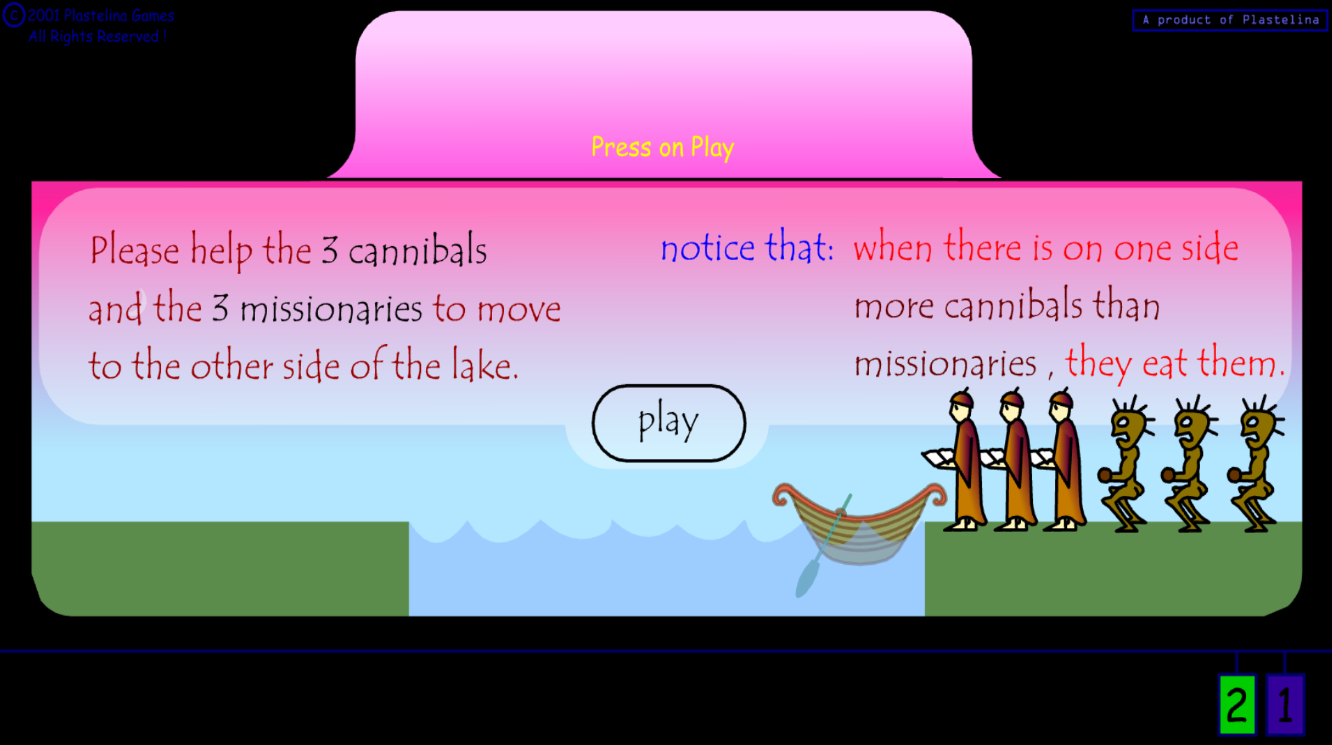

### Problem Statement

- **Three missionaries** and **three cannibals** are together on the **left bank** of a river.
- There is a small rowboat that can carry **at most two people** at a time.
- The boat requires **at least one person** to row it across the river (it cannot move by itself).
- **Critical Safety Constraint:** At no point on either riverbank may the **cannibals outnumber the missionaries** (if there are any missionaries on that bank). If cannibals ever outnumber missionaries on either bank, the missionaries will be eaten.
- **Objective:** Find an optimal sequence of boat crossings to safely transport all six individuals (3 missionaries and 3 cannibals) from the **left bank** to the **right bank**.

> 📺 **Video Reference:** [Watch the Problem Explanation on YouTube](https://youtu.be/DIvTFkx0xwA?si=MH9j1-Wuv74obcBO)

### Learning Objectives

In this notebook, you will learn how to:
1. **Formulate the state space** as an immutable tuple `(M, C, Boat)`.
2. **Implement safety rules** using a constraint-checking function (`is_valid`).
3. **Construct the state space graph** by systematically modeling all legal boat moves.
4. **Apply Breadth-First Search (BFS)** to guarantee finding the shortest path (minimum number of river crossings).
5. **Trace the search process** level by level and verify every transition along the solution path.

## 2. State Space Representation & Constraints

To solve this problem using search algorithms, we first formalize it into a graph search problem.

### State Representation

We can fully describe any configuration of the puzzle using a 3-element tuple:

$$\text{State} = (\text{missionary\_left},\; \text{cannibal\_left},\; \text{boat})$$

Where:
- `missionary_left` $\in \{0, 1, 2, 3\}$: Number of missionaries on the **left bank**.
- `cannibal_left` $\in \{0, 1, 2, 3\}$: Number of cannibals on the **left bank**.
- `boat` $\in \{0, 1\}$: Current location of the boat:
  - `0`: Boat is on the **left bank**.
  - `1`: Boat is on the **right bank**.

Because the total population is conserved (3 missionaries and 3 cannibals in total), the counts on the **right bank** are implicitly derived:

- $\text{missionary\_right} = 3 - \text{missionary\_left}$
- $\text{cannibal\_right} = 3 - \text{cannibal\_left}$

### Initial and Goal States

- **Initial State:** `(3, 3, 0)` — All 3 missionaries, 3 cannibals, and the boat are on the left bank.
- **Goal State:** `(0, 0, 1)` — 0 missionaries, 0 cannibals, and the boat is on the right bank (meaning all 3 missionaries and 3 cannibals are now safely on the right bank).

### Safety & Validity Constraints

A state is considered **valid** if and only if:
1. **Bounds Check:** $0 \le \text{missionary\_left} \le 3$ and $0 \le \text{cannibal\_left} \le 3$.
2. **Left Bank Safety:** If there is at least one missionary on the left bank ($\text{missionary\_left} > 0$), then $\text{cannibal\_left} \le \text{missionary\_left}$.
3. **Right Bank Safety:** If there is at least one missionary on the right bank ($\text{missionary\_right} > 0$), then $\text{cannibal\_right} \le \text{missionary\_right}$.

> **Note:** If a bank has **zero missionaries**, any number of cannibals can be present without harm, as there are no missionaries to be eaten!

In [10]:
def is_valid(state: tuple[int, int, int]) -> bool:
    missionary_left, cannibal_left, boat = state

    missionary_right = 3 - missionary_left
    cannibal_right   = 3 - cannibal_left

    # Check bounds (counts must be between 0 and 3)
    if not (0 <= missionary_left <= 3 and 0 <= cannibal_left <= 3):
        return False

    # Left bank safety constraint
    if missionary_left > 0 and cannibal_left > missionary_left:
        return False

    # Right bank safety constraint
    if missionary_right > 0 and cannibal_right > missionary_right:
        return False

    return True

### Valid vs. Invalid State Examples

Let's test `is_valid` with a few representative states to see how the rules are applied:

| State `(M, C, B)` | Left Bank | Right Bank | Valid? | Reason |
|:---:|:---:|:---:|:---:|:---|
| `(3, 3, 0)` | 3M, 3C | 0M, 0C | **Valid** | Initial state; counts are balanced on the left bank. |
| `(2, 3, 0)` | 2M, 3C | 1M, 0C | **Invalid** | Left bank has 3 cannibals and only 2 missionaries ($3 > 2$). |
| `(1, 1, 1)` | 1M, 1C | 2M, 2C | **Valid** | Both banks have equal numbers of missionaries and cannibals. |
| `(2, 1, 1)` | 2M, 1C | 1M, 2C | **Invalid** | Right bank has 2 cannibals and 1 missionary ($2 > 1$). |
| `(0, 2, 1)` | 0M, 2C | 3M, 1C | **Valid** | 0 missionaries on left (safe); 3M > 1C on right (safe). |

Out of $4 \times 4 \times 2 = 32$ mathematically possible tuples, exactly **20 states** satisfy all constraints.

## 3. Transition Rules & Graph Construction

### Allowed Boat Moves

The boat can carry at most **two people** and at least **one person** (to steer). Thus, five distinct combinations of passengers `(m, c)` can cross:

1. `(1, 0)`: 1 missionary
2. `(0, 1)`: 1 cannibal
3. `(1, 1)`: 1 missionary and 1 cannibal
4. `(2, 0)`: 2 missionaries
5. `(0, 2)`: 2 cannibals

### Direction of Boat Travel

- **If `boat == 0` (Left $\to$ Right):**
  - Missionaries on left decrease: $\text{missionary\_left} - m$
  - Cannibals on left decrease: $\text{cannibal\_left} - c$
  - Boat moves to right: $\text{boat} = 1$
- **If `boat == 1` (Right $\to$ Left):**
  - Missionaries on left increase: $\text{missionary\_left} + m$
  - Cannibals on left increase: $\text{cannibal\_left} + c$
  - Boat moves to left: $\text{boat} = 0$

### Pruning Transitions

A transition from `state` to `next_state` is only allowed if:
1. The bank where the boat is departing has enough people to board the boat ($m \le M_{\text{depart}}$ and $c \le C_{\text{depart}}$).
2. The resulting `next_state` is a valid, safe state (`is_valid(next_state) == True`).

We construct the problem as an **Adjacency List** dictionary where each state maps to its list of reachable valid neighbor states.

In [11]:
from itertools import product

def build_graph() -> dict:
    graph = {}

    # Generate all valid states (20 valid configurations)
    states = [
        (m, c, boat)
        for m, c, boat in product(range(4), range(4), range(2))
        if is_valid((m, c, boat))
    ]

    # Possible boat passenger configurations: (missionaries, cannibals)
    # Capacity is 1 or 2 passengers
    moves = [
        (1, 0),    # One missionary
        (0, 1),    # One cannibal
        (1, 1),    # One missionary and one cannibal
        (2, 0),    # Two missionaries
        (0, 2),    # Two cannibals
    ]

    for state in states:
        missionary_left, cannibal_left, boat = state
        graph[state] = []

        for m, c in moves:
            if boat == 0:
                # Boat moves from Left to Right
                next_state = (missionary_left - m, cannibal_left - c, 1)
            elif boat == 1:
                # Boat moves from Right to Left
                next_state = (missionary_left + m, cannibal_left + c, 0)

            # Check passenger availability on the departure bank and state validity
            if next_state in states:
                if boat == 0 and (m > missionary_left or c > cannibal_left):
                    continue
                if boat == 1 and (m > 3 - missionary_left or c > 3 - cannibal_left):
                    continue

                if next_state not in graph[state]:
                    graph[state].append(next_state)

    return graph

## 4. Breadth-First Search (BFS) Implementation

### Why Breadth-First Search?

1. **Uniform Edge Costs:** Every river crossing counts as 1 step (unit cost $c = 1$).
2. **Optimal Path Guarantee:** BFS explores states level by level (in order of increasing path length). The first time it discovers the goal state `(0, 0, 1)`, that path is mathematically guaranteed to have the **minimum number of river crossings**.
3. **Cycle Handling:** Since the boat can travel back and forth between banks, the state graph contains cycles. The `visited` set ensures that no state is re-added to the queue, avoiding infinite loops.

### Algorithm Outline

1. Initialize a queue (FIFO) with a path containing only the `start` state: `deque([[start]])`.
2. Maintain a `visited` set initialized with `{start}`.
3. While the queue is not empty:
   - Pop the oldest path from the left of the queue.
   - Inspect the current node (`path[-1]`).
   - Iterate over its valid outgoing neighbors:
     - If a neighbor is the `goal`, return the complete path immediately (`path + [neighbor]`).
     - If the neighbor has not been `visited`, mark it as visited and push `path + [neighbor]` into the queue.

In [12]:
from collections import deque

def bfs(graph: dict, start: tuple, goal: tuple) -> list | None:
    if start == goal:
        return [start]

    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        node = path[-1]

        for neighbor in graph.get(node, []):
            if neighbor == goal:
                return path + [neighbor]

            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(path + [neighbor])

    return None

## 5. Running BFS & Finding the Solution

Now we construct the graph and execute BFS starting from `(3, 3, 0)` with target `(0, 0, 1)`.

We also format the solution into a clear, human-readable summary of every river crossing.

In [14]:
graph = build_graph()

start = (3, 3, 0)
goal  = (0, 0, 1)

path  = bfs(graph, start, goal)

print(path)

[(3, 3, 0), (2, 2, 1), (3, 2, 0), (3, 0, 1), (3, 1, 0), (1, 1, 1), (2, 2, 0), (0, 2, 1), (0, 3, 0), (0, 1, 1), (1, 1, 0), (0, 0, 1)]


## 6. Step-by-Step Execution & Tracing

To thoroughly understand how Breadth-First Search navigates the state space and why this solution works, let's examine two comprehensive traces:
1. The **BFS Search Frontier Trace** (how the search algorithm discovers and expands states).
2. The **Physical River-Crossing Trace** (how the missionaries and cannibals move across the river safely).

---

### 6.1 BFS Search Frontier Trace

The table below records each iteration of the BFS `while queue:` loop. 
- `Step`: The loop iteration number.
- `node`: The state currently popped from the front of the queue (`path[-1]`).
- `Newly Discovered`: Neighbors of `node` that are not yet in `visited` and are added to the queue.
- `Queue Size`: Number of paths remaining in the queue after expanding `node`.

| Step | Current State (`node`) | Path Length | Newly Discovered Neighbors | Queue Size | Status |
|:---:|:---:|:---:|:---|:---:|:---|
| **Initial** | — | 0 | `(3, 3, 0)` | 1 | Start state added to queue |
| **1** | `(3, 3, 0)` | 1 | `(3, 2, 1)`, `(2, 2, 1)`, `(3, 1, 1)` | 3 | Explores level 1 crossings (1C, 1M+1C, 2C) |
| **2** | `(3, 2, 1)` | 2 | *None* (return move leads to visited `(3, 3, 0)`) | 2 | Dead end / cycle pruned |
| **3** | `(2, 2, 1)` | 2 | `(3, 2, 0)` | 2 | Sends 1M back to left bank |
| **4** | `(3, 1, 1)` | 2 | *None* (return move `(3, 2, 0)` is already visited) | 1 | Dead end / duplicate state pruned |
| **5** | `(3, 2, 0)` | 3 | `(3, 0, 1)` | 1 | Sends 2C across to right bank |
| **6** | `(3, 0, 1)` | 4 | `(3, 1, 0)` | 1 | Returns 1C to left bank |
| **7** | `(3, 1, 0)` | 5 | `(1, 1, 1)` | 1 | Sends 2M across to right bank |
| **8** | `(1, 1, 1)` | 6 | `(2, 2, 0)` | 1 | Returns 1M and 1C to left bank |
| **9** | `(2, 2, 0)` | 7 | `(0, 2, 1)` | 1 | Sends 2M across to right bank |
| **10** | `(0, 2, 1)` | 8 | `(0, 3, 0)` | 1 | Returns 1C to left bank |
| **11** | `(0, 3, 0)` | 9 | `(0, 1, 1)` | 1 | Sends 2C across to right bank |
| **12** | `(0, 1, 1)` | 10 | `(1, 1, 0)`, `(0, 2, 0)` | 2 | Discovers return options (1M or 1C) |
| **13** | `(1, 1, 0)` | 11 | **`(0, 0, 1)` (GOAL!)** | 1 | **Goal reached! Search terminates.** |

> **Key Insight from BFS Tracing:**
> Notice how narrow the state space is! At almost every level, there is only **one** safe forward transition that does not cycle back to an already visited state. BFS explores only 13 nodes before reaching the goal.

---

### 6.2 Physical River-Crossing Narrative

Here is the detailed narrative of each crossing, explaining why no missionary is eaten at any stage:

| Step | Action Taken | Left Bank `(M, C)` | Boat | Right Bank `(M, C)` | Why It Is Safe |
|:---:|:---|:---:|:---:|:---:|:---|
| **0** | *Starting position* | **3M, 3C** | **Left** | **0M, 0C** | Everyone is on the left bank ($3 = 3$). |
| **1** | 1 Missionary & 1 Cannibal cross **L $\to$ R** | **2M, 2C** | **Right** | **1M, 1C** | Both banks have equal numbers ($2 = 2$ and $1 = 1$). |
| **2** | 1 Missionary returns **R $\to$ L** | **3M, 2C** | **Left** | **0M, 1C** | Left has $3M > 2C$; Right has 0 missionaries (safe). |
| **3** | 2 Cannibals cross **L $\to$ R** | **3M, 0C** | **Right** | **0M, 3C** | Left has only missionaries; Right has only cannibals. |
| **4** | 1 Cannibal returns **R $\to$ L** | **3M, 1C** | **Left** | **0M, 2C** | Left has $3M > 1C$; Right has 0 missionaries. |
| **5** | 2 Missionaries cross **L $\to$ R** | **1M, 1C** | **Right** | **2M, 2C** | **Crucial move:** Left has $1M = 1C$; Right has $2M = 2C$. |
| **6** | 1 Missionary & 1 Cannibal return **R $\to$ L** | **2M, 2C** | **Left** | **1M, 1C** | Balances both sides: $2 = 2$ on left, $1 = 1$ on right. |
| **7** | 2 Missionaries cross **L $\to$ R** | **0M, 2C** | **Right** | **3M, 1C** | All 3 missionaries are now on the right bank ($3M > 1C$). Left has 0 missionaries. |
| **8** | 1 Cannibal returns **R $\to$ L** | **0M, 3C** | **Left** | **3M, 0C** | Left has only cannibals; Right has only missionaries. |
| **9** | 2 Cannibals cross **L $\to$ R** | **0M, 1C** | **Right** | **3M, 2C** | Right bank has $3M > 2C$ (missionaries safe). |
| **10** | 1 Missionary returns **R $\to$ L** | **1M, 1C** | **Left** | **2M, 2C** | Alternatively, 1 cannibal can return to reach `(0, 2, 0)`. Left has $1 = 1$, Right has $2 = 2$. |
| **11** | 1 Missionary & 1 Cannibal cross **L $\to$ R** | **0M, 0C** | **Right** | **3M, 3C** | **Goal reached!** Everyone has crossed safely. |

## 7. Complexity Analysis

### State Space & Graph Size

- **Total Theoretical States:** $4 \times 4 \times 2 = 32$ configurations.
- **Total Valid States ($|V|$):** $20$ states satisfy the safety constraints.
- **Total Directed Edges ($|E|$):** $56$ legal directed transitions between valid states.
- **Branching Factor ($b$):** Between $1$ and $5$ valid actions per state.

### Time Complexity

- Standard BFS visiting every vertex and edge runs in **$\mathcal{O}(|V| + |E|)$** time.
- Because path reconstruction stores full paths in the queue:
  $$\text{Time Complexity} = \mathcal{O}(|V|^2 + |E|)$$
- In practice, with $|V| = 20$, the BFS terminates in less than **1 millisecond** after visiting only 13 states.

### Space Complexity

- **Queue (Frontier):** Holds the paths waiting to be expanded. In our trace, the maximum queue size was only **3 paths**.
- **Visited Set:** Stores at most $|V|$ states: **$\mathcal{O}(|V|)$**.
- Overall auxiliary memory is bounded by **$\mathcal{O}(|V|)$**.

### Optimality and Completeness

- **Completeness:** Yes. The state space is finite, and the `visited` set guarantees BFS never enters an infinite loop.
- **Optimality:** Yes. Since all boat crossings have identical step cost ($c = 1$), BFS is guaranteed to return a path with the **minimum number of crossings** (11 crossings).